# 08 · Prepago (el "churn" del crédito) y severidad (LGD)

La política de la decisión 008 usa promedios por subgrado para lo que rinde un préstamo **si sale bueno** (`r_bueno`) y lo que se pierde **si sale malo** (`r_malo`):

    utilidad esperada = monto × [(1 − PD) × r_bueno + PD × r_malo]

Esta sesión los vuelve **personales** con 5 opciones (decisión 010):

| Familia | Opción | Qué predice |
|---|---|---|
| Prepago | A · Clasificación | P(pagar todo antes del mes 30) |
| Prepago | B · Regresión | r_bueno directamente |
| Prepago | C · Supervivencia | Curva mes a mes de pagar todo → interés esperado con la tabla de amortización |
| Severidad | A · LGD clásica (Basilea) | % de la exposición que no se recupera |
| Severidad | B · Pérdida económica | r_malo directamente |

**Criterio fijado antes de entrenar:** en 2015, (1) MAE y RMSE contra el valor real (el RMSE castiga más los errores grandes), (2) Spearman y (3) utilidad de la política en jul–dic 2015. Línea base: el promedio por subgrado.

Entrenamiento: `python -m credit_lab.entrenar_economia` (código en `prepago.py` y `severidad.py`).

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from credit_lab.poblacion import cargar_poblacion
from credit_lab.prepago import rendimiento, meses_pago, interes_hasta_mes
from credit_lab.severidad import lgd, ead
from credit_lab.campeon import cargar

pd.set_option("display.float_format", "{:,.4f}".format)
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e5e4df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.titlecolor": TINTA, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
M = "../modelos/"
pred = pd.read_parquet(M + "predicciones_economia_oot.parquet")
df = cargar_poblacion()
tr, oot = df[df["muestra"].eq("train")], df.loc[pred.index]
r = rendimiento(oot)
bueno, malo = oot["malo"].eq(0), oot["malo"].eq(1)

## 1. Prepago: el comportamiento que se come la ganancia

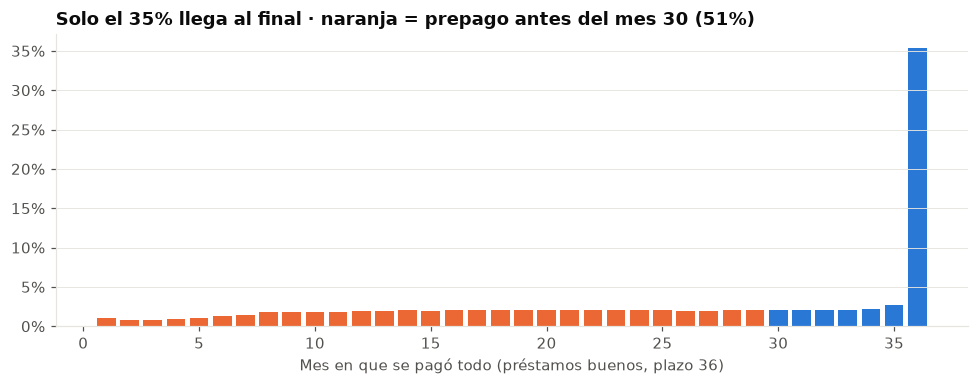

In [2]:
b_tr = tr[tr["malo"].eq(0)]
meses = meses_pago(b_tr)
fig, ax = plt.subplots(figsize=(9, 3.6))
dist = meses.value_counts(normalize=True).sort_index()
ax.bar(dist.index, dist.values, color=[NARANJA if m < 30 else AZUL for m in dist.index], width=0.8)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", visible=False)
ax.set_xlabel("Mes en que se pagó todo (préstamos buenos, plazo 36)")
ax.set_title(f"Solo el {(meses == 36).mean():.0%} llega al final · naranja = prepago antes del mes 30 ({(meses < 30).mean():.0%})")
fig.tight_layout()

In [3]:
teo = interes_hasta_mes(b_tr["int_rate"].to_numpy(), meses.to_numpy())
real = rendimiento(b_tr).to_numpy()
print(f"La tabla de amortización explica el rendimiento real: correlación {np.corrcoef(teo, real)[0, 1]:.3f} · error medio {np.abs(teo - real).mean():.4f}")
print("→ si se predice bien CUÁNDO paga, se sabe CUÁNTO rinde (base de la opción C).")

La tabla de amortización explica el rendimiento real: correlación 0.995 · error medio 0.0026
→ si se predice bien CUÁNDO paga, se sabe CUÁNTO rinde (base de la opción C).


### Las 3 opciones de prepago en 2015 (préstamos buenos)

In [4]:
opciones_p = {"Línea base (promedio por subgrado)": "prepago_base", "A · Clasificación": "prepago_a_clasificacion",
              "B · Regresión": "prepago_b_regresion", "C · Supervivencia": "prepago_c_supervivencia"}
tabla_p = pd.DataFrame({k: {"MAE": np.abs(pred.loc[bueno, v] - r[bueno]).mean(),
                            "RMSE": np.sqrt(((pred.loc[bueno, v] - r[bueno]) ** 2).mean()),
                            "spearman": spearmanr(pred.loc[bueno, v], r[bueno])[0],
                            "r_bueno_medio_predicho": pred.loc[bueno, v].mean(),
                            "r_bueno_medio_real": r[bueno].mean()} for k, v in opciones_p.items()}).T
print(f"AUC del clasificador de prepago (opción A): {roc_auc_score((meses_pago(oot[bueno]) < 30).astype(int), pred.loc[bueno, 'prob_prepago']):.3f}")
tabla_p

AUC del clasificador de prepago (opción A): 0.633


,MAE,RMSE,spearman,r_bueno_medio_predicho,r_bueno_medio_real
Línea base (promedio por subgrado),0.0349,0.0544,0.6441,0.1605,0.1424
A · Clasificación,0.0338,0.0540,0.6650,0.1629,0.1424
B · Regresión,0.0336,0.0558,0.6659,0.1665,0.1424
C · Supervivencia,0.0353,0.0497,0.6673,0.1472,0.1424


**Lectura:** en 2015 los buenos prepagaron **más** que en 2012–2014 (rindieron 14,2% contra el 16,1% que asumía el promedio). La **supervivencia** es la que mejor capta ese nivel (14,7%) porque combina la tasa de cada préstamo con su curva de pago, y es la que mejor ordena (Spearman). La regresión tiene el menor MAE por poco, pero el **peor RMSE**: se entrenó con objetivo L1 (minimiza el error absoluto) y comete errores grandes con algunos clientes. La supervivencia tiene el **mejor RMSE por lejos** (0,0497): casi nunca se equivoca por mucho, que es lo que importa al decidir créditos.

### Curvas de supervivencia: tres clientes

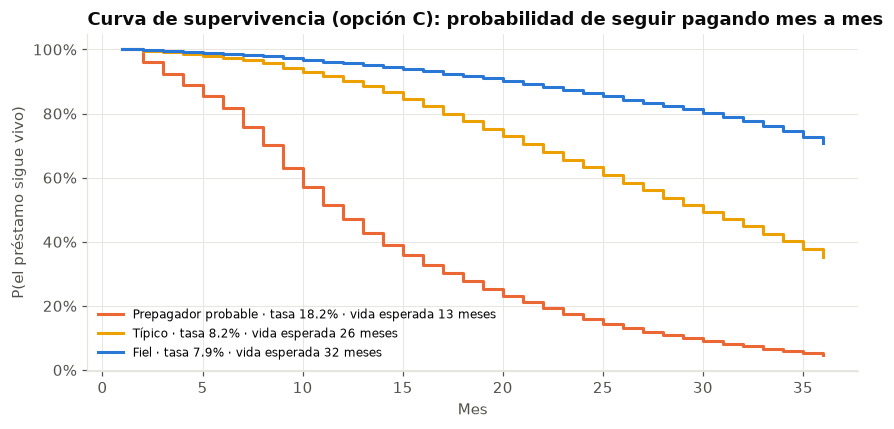

In [5]:
superv = joblib.load(M + "prepago_c_supervivencia.joblib")
muestra = oot[bueno].sample(3000, random_state=1)
dist_m = superv.distribucion(muestra)
vida = (dist_m * np.arange(1, 37)).sum(axis=1)
idx = [np.argmin(vida), np.argsort(vida)[len(vida) // 2], np.argmax(vida)]
fig, ax = plt.subplots(figsize=(8, 4))
for i, color, nombre in zip(idx, [NARANJA, AMARILLO, AZUL], ["Prepagador probable", "Típico", "Fiel"]):
    vivo = 1 - np.cumsum(dist_m[i])
    fila = muestra.iloc[i]
    ax.step(range(1, 37), np.r_[1, vivo[:-1]], where="post", color=color, linewidth=2,
            label=f"{nombre} · tasa {fila['int_rate']:.1f}% · vida esperada {vida[i]:.0f} meses")
ax.set_xlabel("Mes")
ax.set_ylabel("P(el préstamo sigue vivo)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Curva de supervivencia (opción C): probabilidad de seguir pagando mes a mes")
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()

## 2. Severidad: cuánto se pierde cuando cae

EAD media: 58.3% del monto · LGD real media: 89.2%
LGD clásica · MAE 0.0827 vs promedio 0.0826 · RMSE 0.1285 vs promedio 0.1281 · Spearman 0.108 · R² -0.006


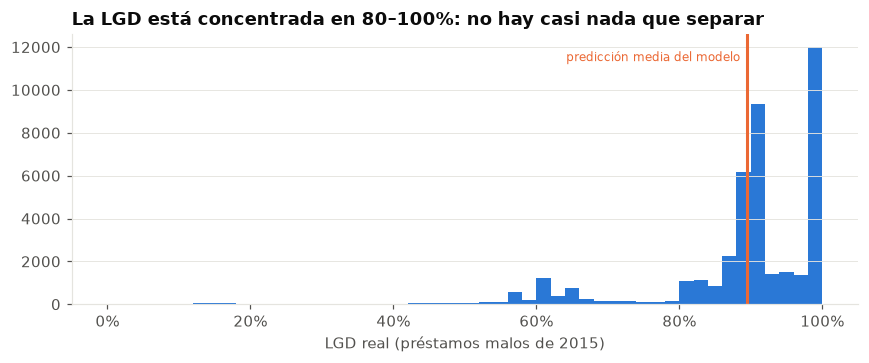

In [6]:
m_oot = oot[malo]
lgd_real = lgd(m_oot)
lgd_pred = joblib.load(M + "severidad_a_lgd.joblib").predecir_lgd(m_oot)
print(f"EAD media: {(ead(m_oot) / m_oot['funded_amnt']).mean():.1%} del monto · LGD real media: {lgd_real.mean():.1%}")
rmse = lambda e: np.sqrt((e ** 2).mean())
print(f"LGD clásica · MAE {np.abs(lgd_pred - lgd_real).mean():.4f} vs promedio {np.abs(lgd_real.mean() - lgd_real).mean():.4f}"
      f" · RMSE {rmse(lgd_pred - lgd_real):.4f} vs promedio {rmse(lgd_real.mean() - lgd_real):.4f}"
      f" · Spearman {spearmanr(lgd_pred, lgd_real)[0]:.3f} · R² {1 - ((lgd_pred - lgd_real) ** 2).sum() / ((lgd_real - lgd_real.mean()) ** 2).sum():.3f}")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(lgd_real, bins=50, color=AZUL)
ax.axvline(lgd_pred.mean(), color=NARANJA, linewidth=2)
ax.text(lgd_pred.mean() - 0.01, ax.get_ylim()[1] * 0.9, "predicción media del modelo", ha="right", color=NARANJA, fontsize=8)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", visible=False)
ax.set_xlabel("LGD real (préstamos malos de 2015)")
ax.set_title("La LGD está concentrada en 80–100%: no hay casi nada que separar")
fig.tight_layout()

In [7]:
opciones_s = {"Línea base (promedio por subgrado)": "severidad_base", "A · LGD clásica": "severidad_a_lgd",
              "B · Pérdida económica": "severidad_b_economica"}
pd.DataFrame({k: {"MAE": np.abs(pred.loc[malo, v] - r[malo]).mean(),
                  "RMSE": np.sqrt(((pred.loc[malo, v] - r[malo]) ** 2).mean()),
                  "spearman": spearmanr(pred.loc[malo, v], r[malo])[0],
                  "r_malo_medio_predicho": pred.loc[malo, v].mean(),
                  "r_malo_medio_real": r[malo].mean()} for k, v in opciones_s.items()}).T

,MAE,RMSE,spearman,r_malo_medio_predicho,r_malo_medio_real
Línea base (promedio por subgrado),0.2344,0.2772,0.0337,-0.3574,-0.3858
A · LGD clásica,0.2344,0.2772,0.0052,-0.3604,-0.3858
B · Pérdida económica,0.2323,0.2756,0.1220,-0.3572,-0.3858


**Lectura:** el modelo de **LGD clásica ordena un poco** (Spearman 0,11) **pero no mejora el error frente al promedio** (R² ≈ 0). No es un error del modelo: es la evidencia de que en Lending Club la recuperación era baja y pareja (la deuda castigada se vendía a agencias), así que hay muy poco que predecir. La **pérdida económica** sí tiene algo de señal (Spearman 0,12 contra 0,03), porque captura **cuándo** cae el préstamo: el que cae tarde ya devolvió capital e intereses.

## 3. El examen de negocio: utilidad de la política en jul–dic 2015

In [8]:
campeon = cargar()
s2 = (oot["issue_d"].dt.month > 6).to_numpy()
o2, p2 = oot[s2], pred[s2]
pd2 = campeon.pd(o2)
u = (rendimiento(o2) * o2["funded_amnt"]).to_numpy()
F = o2["funded_amnt"].to_numpy()

def aprobados(rb, rm):
    return F * ((1 - pd2) * p2[rb].to_numpy() + pd2 * p2[rm].to_numpy()) > 0

combos = {"Base + base (decisión 008)": ("prepago_base", "severidad_base"),
          "A clasificación + base": ("prepago_a_clasificacion", "severidad_base"),
          "B regresión + base": ("prepago_b_regresion", "severidad_base"),
          "C supervivencia + base": ("prepago_c_supervivencia", "severidad_base"),
          "Base + A LGD clásica": ("prepago_base", "severidad_a_lgd"),
          "Base + B pérdida económica": ("prepago_base", "severidad_b_economica"),
          "C supervivencia + B pérdida económica": ("prepago_c_supervivencia", "severidad_b_economica")}
ap = {k: aprobados(*v) for k, v in combos.items()}
ref = ap["Base + base (decisión 008)"]
rng = np.random.default_rng(0)
boots = [rng.integers(0, len(u), len(u)) for _ in range(500)]
filas = {}
for k, a in ap.items():
    d = np.array([(u[i] * a[i]).sum() - (u[i] * ref[i]).sum() for i in boots]) / 1e6
    filas[k] = {"aprobación": a.mean(), "utilidad_M": u[a].sum() / 1e6, "vs_aprobar_todo_M": (u[a].sum() - u.sum()) / 1e6,
                "vs_decisión_008_M": (u[a].sum() - u[ref].sum()) / 1e6, "IC95_inf": np.percentile(d, 2.5),
                "IC95_sup": np.percentile(d, 97.5), "roi": u[a].sum() / F[a].sum(), "mora": o2["malo"].to_numpy()[a].mean()}
pd.DataFrame(filas).T

,aprobación,utilidad_M,vs_aprobar_todo_M,vs_decisión_008_M,IC95_inf,IC95_sup,roi,mora
Base + base (decisión 008),0.9824,128.8400,0.6484,0.0000,0.0000,0.0000,0.0630,0.1439
A clasificación + base,0.9861,128.8393,0.6477,-0.0008,-0.2092,0.2714,0.0628,0.1445
B regresión + base,0.9871,128.7604,0.5688,-0.0797,-0.3525,0.2353,0.0627,0.1449
C supervivencia + base,0.9761,128.9701,0.7785,0.1301,-0.1617,0.4353,0.0635,0.1433
Base + A LGD clásica,0.9798,128.6408,0.4492,-0.1992,-0.3593,-0.0426,0.0630,0.1437
Base + B pérdida económica,0.9797,128.9153,0.7237,0.0753,-0.2398,0.3675,0.0632,0.1436
C supervivencia + B pérdida económica,0.9718,129.0866,0.8950,0.2466,-0.1226,0.6884,0.0637,0.1427


**Lectura honesta:** la combinación **C supervivencia + B pérdida económica** es la mejor en todo (utilidad, ROI y mora), pero su ventaja sobre la decisión 008 (+USD 0,25 M) **no es estadísticamente significativa**: el intervalo incluye el cero. La personalización mejora el ordenamiento, pero el precio de Lending Club ya capturaba casi todo el valor.

---
## ✍️ Conclusiones de Neider

1. En crédito el churn es el prepago: solo el 35% de los buenos llega al final del plazo, y el que prepaga antes del mes 30 rinde 13% en vez de 20%. En 2015 se prepagó más que antes y el promedio sobreestimaba la ganancia.
2. La supervivencia es la mejor forma de modelar el prepago: capta el nivel real de 2015, ordena mejor y tiene el menor RMSE, o sea que casi nunca se equivoca por mucho. Además da la vida esperada de cada préstamo, que necesito para el pricing.
3. La LGD clásica no sirvió en esta cartera: el 92% está entre 80% y 100% porque Lending Club recuperaba poco y parejo. Usarla en la política incluso empeoró la utilidad. La pérdida económica sí tiene señal porque captura cuándo cae el préstamo.
4. La mejor combinación (supervivencia + pérdida económica) sube la utilidad, el ROI y baja la mora, pero la ganancia no es significativa: el precio de Lending Club ya capturaba casi todo el valor. La elijo porque es la mejor en todo y sirve para el pricing.